In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv('salary_analys.csv')
print(df.head())
print(df.tail())

  EmployeeID RoleLevel  ExperienceYears   Department           City Education  \
0    EMP0001    Junior                4  Engineering       New York  Bachelor   
1    EMP0002   Manager               12    Marketing  San Francisco  Bachelor   
2    EMP0003    Junior                0   Operations         Austin  Bachelor   
3    EMP0004    Senior                8        Sales         Austin    Master   
4    EMP0005       Mid                3   Operations         Austin  Bachelor   

      Salary  
0   85114.37  
1  214607.86  
2   44173.58  
3  146382.84  
4   73578.53  
     EmployeeID RoleLevel  ExperienceYears   Department           City  \
1495    EMP1496    Senior               14  Engineering         Austin   
1496    EMP1497    Junior                2           HR  San Francisco   
1497    EMP1498    Junior                2    Marketing        Seattle   
1498    EMP1499       Mid                8        Sales         Denver   
1499    EMP1500    Senior               14    Marketi

In [ ]:
print(df.shape)

(1500, 7)


In [ ]:
print(df.columns)

Index(['EmployeeID', 'RoleLevel', 'ExperienceYears', 'Department', 'City',
       'Education', 'Salary'],
      dtype='object')


In [ ]:
print(df.dtypes)

EmployeeID          object
RoleLevel           object
ExperienceYears      int64
Department          object
City                object
Education           object
Salary             float64
dtype: object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   EmployeeID       1500 non-null   object 
 1   RoleLevel        1500 non-null   object 
 2   ExperienceYears  1500 non-null   int64  
 3   Department       1500 non-null   object 
 4   City             1500 non-null   object 
 5   Education        1500 non-null   object 
 6   Salary           1500 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 82.2+ KB


In [ ]:
df.isnull().sum()

,0
EmployeeID,0
RoleLevel,0
ExperienceYears,0
Department,0
City,0
Education,0
Salary,0


In [ ]:
df.describe()

,ExperienceYears,Salary
count,1500.000000,1500.000000
mean,7.322000,119931.862253
std,5.570787,69399.083806
min,0.000000,35795.160000
25%,3.000000,71208.957500
50%,6.000000,99620.005000
75%,11.000000,143970.070000
max,29.000000,567020.500000


In [ ]:
print(df.groupby("RoleLevel"))

In [ ]:
df.groupby("RoleLevel")['Salary'].mean()

,Salary
RoleLevel,
Director,292764.638851
Junior,66148.689444
Manager,209458.458250
Mid,97025.320533
Senior,138193.837552


In [ ]:
df.value_counts()

,,,,,,,count
EmployeeID,RoleLevel,ExperienceYears,Department,City,Education,Salary,
EMP1500,Senior,14,Marketing,Austin,Master,147027.33,1
EMP0001,Junior,4,Engineering,New York,Bachelor,85114.37,1
EMP0002,Manager,12,Marketing,San Francisco,Bachelor,214607.86,1
EMP0003,Junior,0,Operations,Austin,Bachelor,44173.58,1
EMP0004,Senior,8,Sales,Austin,Master,146382.84,1
...,...,...,...,...,...,...,...
EMP0017,Manager,15,Finance,Denver,Master,207955.35,1
EMP0016,Director,26,Sales,San Francisco,Master,389842.50,1
EMP0015,Manager,15,Finance,Denver,Bachelor,190994.07,1


In [ ]:
df.groupby("Department")["Salary"].mean()

,Salary
Department,
Engineering,135348.599686
Finance,127409.391829
HR,106795.021372
Marketing,115338.880644
Operations,107834.107059
Sales,127173.276813


In [ ]:
df.groupby("Department")["Salary"].mean().sort_values(ascending=False)

,Salary
Department,
Engineering,135348.599686
Finance,127409.391829
Sales,127173.276813
Marketing,115338.880644
Operations,107834.107059
HR,106795.021372


In [ ]:
df["ExperienceYears"].corr(df["Salary"])

np.float64(0.8206156225400931)

In [ ]:
df["Salary"].max()

567020.5

In [ ]:
df["Salary"].idxmax()

218

In [ ]:
df.loc[df["Salary"].idxmax()]

,218
EmployeeID,EMP0219
RoleLevel,Director
ExperienceYears,15
Department,Operations
City,Seattle
Education,High School
Salary,567020.5


In [ ]:
df.loc[df["Salary"].idxmin()]

,515
EmployeeID,EMP0516
RoleLevel,Junior
ExperienceYears,0
Department,HR
City,Denver
Education,High School
Salary,35795.16


<Axes: >

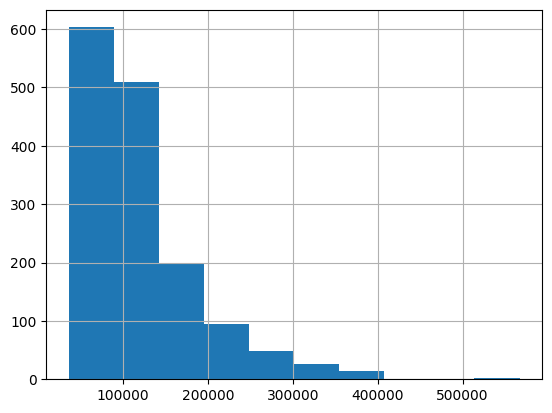

In [ ]:
df["Salary"].hist()

<Axes: xlabel='Department'>

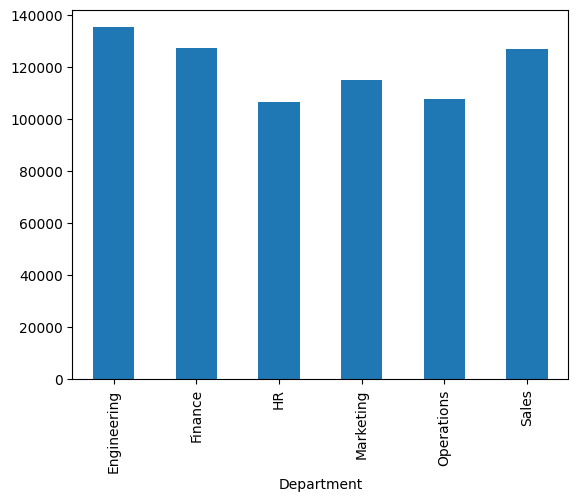

In [ ]:
df.groupby("Department")["Salary"].mean().plot(kind="bar")

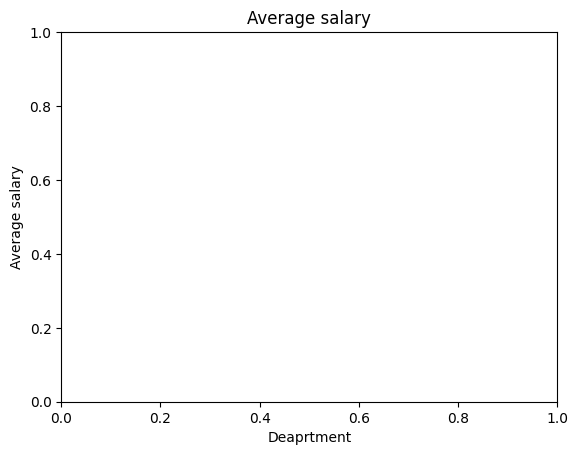

In [ ]:
import matplotlib.pyplot as plt
plt.title("Average salary")
plt.xlabel("Deaprtment")
plt.ylabel("Average salary")
plt.show()

<Axes: >

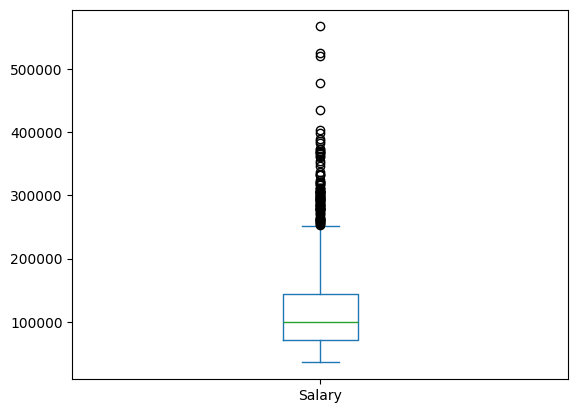

In [ ]:
df["Salary"].plot(kind = "box")

In [ ]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)
print("Q1:", Q1)
print("Q3:", Q3)

Q1: 71208.9575
Q3: 143970.07


In [ ]:
IQR = Q3 - Q1
print("IQR:", IQR)

IQR: 72761.1125


In [ ]:
Q1 = df["Salary"].quantile(0.25)
print(Q1)

71208.9575


In [ ]:
Q3 = df["Salary"].quantile(0.75)
print(Q3)

143970.07


In [ ]:
IQR = (Q3-Q1)
print(IQR)

72761.1125


In [ ]:
low = Q1 - (1.5 * IQR)
print(low)

-37932.71125000001


In [ ]:
upp = Q3 + (1.5 * IQR)
print(upp)

253111.73875000002


In [ ]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -37932.71125000001
Upper bound: 253111.73875000002


In [ ]:
outliers = df[
    (df["Salary"] < lower_bound) |
    (df["Salary"] > upper_bound)
]
print("Number of outliers:", len(outliers))

Number of outliers: 90


In [ ]:
len(outliers)

90

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("salary_analys.csv")
print(df)

     EmployeeID RoleLevel  ExperienceYears   Department           City  \
0       EMP0001    Junior                4  Engineering       New York   
1       EMP0002   Manager               12    Marketing  San Francisco   
2       EMP0003    Junior                0   Operations         Austin   
3       EMP0004    Senior                8        Sales         Austin   
4       EMP0005       Mid                3   Operations         Austin   
...         ...       ...              ...          ...            ...   
1495    EMP1496    Senior               14  Engineering         Austin   
1496    EMP1497    Junior                2           HR  San Francisco   
1497    EMP1498    Junior                2    Marketing        Seattle   
1498    EMP1499       Mid                8        Sales         Denver   
1499    EMP1500    Senior               14    Marketing         Austin   

     Education     Salary  
0     Bachelor   85114.37  
1     Bachelor  214607.86  
2     Bachelor   44173.58  

In [ ]:
outlier_percentage = (len(outliers) / len(df)) * 100
print("Outlier percentage:", outlier_percentage)

Outlier percentage: 6.0


In [ ]:
df.groupby("Education")["Salary"].mean()

,Salary
Education,
Bachelor,115726.313472
High School,100284.324561
Master,133521.807775
PhD,130070.889724


In [ ]:
df.groupby("City")["Salary"].mean().sort_values(ascending=False)

,Salary
City,
San Francisco,139454.594712
New York,125658.851544
Seattle,124566.479201
Austin,109812.066678
Denver,100785.379172


In [ ]:
df["ExperienceYears"].corr(df["Salary"])

np.float64(0.8206156225400931)

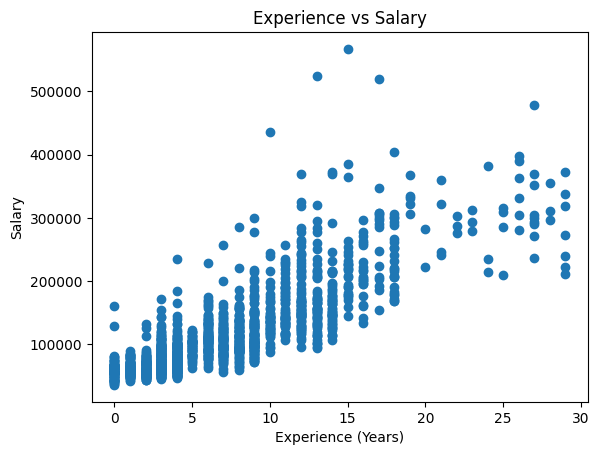

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df["ExperienceYears"], df["Salary"])
plt.title("Experience vs Salary")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.show()

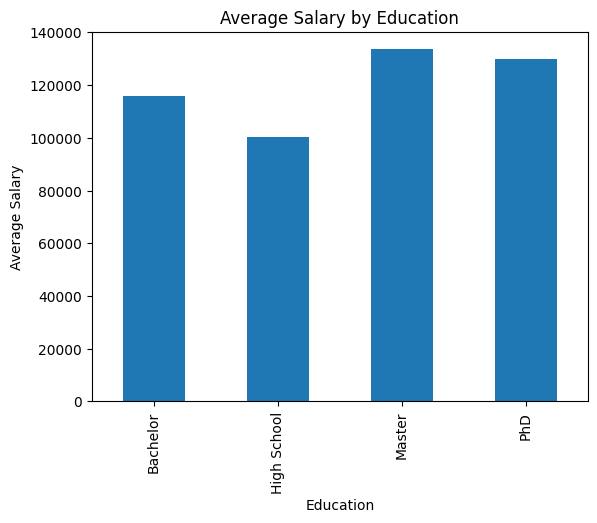

In [ ]:
df.groupby("Education")["Salary"].mean().plot(kind="bar")

plt.title("Average Salary by Education")
plt.xlabel("Education")
plt.ylabel("Average Salary")
plt.show()

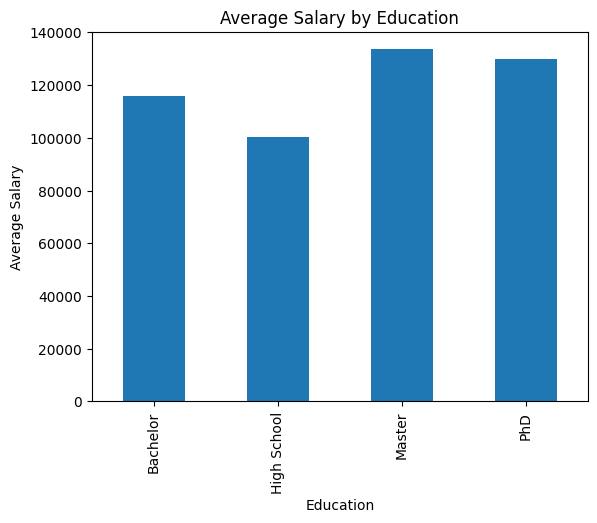

In [ ]:
df.groupby("Education")["Salary"].mean().plot(kind="bar")

plt.title("Average Salary by Education")
plt.xlabel("Education")
plt.ylabel("Average Salary")
plt.show()

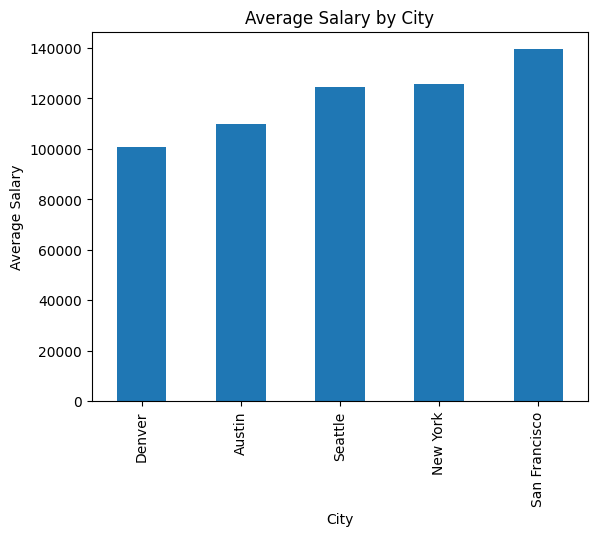

In [ ]:
df.groupby("City")["Salary"].mean().sort_values().plot(kind="bar")

plt.title("Average Salary by City")
plt.xlabel("City")
plt.ylabel("Average Salary")
plt.show()

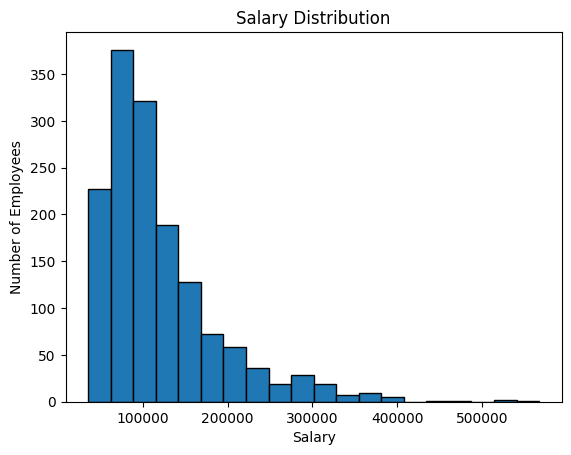

In [ ]:
df["Salary"].plot(kind="hist", bins=20, edgecolor="black")

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.show()

In [ ]:
df.nlargest(5, "Salary")

,EmployeeID,RoleLevel,ExperienceYears,Department,City,Education,Salary
218,EMP0219,Director,15,Operations,Seattle,High School,567020.50
1094,EMP1095,Manager,13,Engineering,Seattle,Bachelor,524420.67
1356,EMP1357,Manager,17,HR,New York,Bachelor,519964.96
1279,EMP1280,Director,27,Engineering,San Francisco,Master,478073.29
979,EMP0980,Manager,10,Finance,Seattle,Master,435715.27


In [ ]:
df.nsmallest(5, "Salary")

,EmployeeID,RoleLevel,ExperienceYears,Department,City,Education,Salary
515,EMP0516,Junior,0,HR,Denver,High School,35795.16
13,EMP0014,Junior,0,HR,Denver,High School,37957.48
707,EMP0708,Junior,0,Operations,Austin,High School,39453.58
1108,EMP1109,Junior,0,HR,Denver,High School,40040.02
1096,EMP1097,Junior,0,HR,Denver,Bachelor,40493.23


In [ ]:
print("Total Employees:", len(df))
print("Average Salary:", df["Salary"].mean())
print("Median Salary:", df["Salary"].median())
print("Minimum Salary:", df["Salary"].min())
print("Maximum Salary:",df["Salary"].max())
print("Average Experience:", df["ExperienceYears"].mean())
print("Missing Values:", df.isnull().sum().sum())

Total Employees: 1500
Average Salary: 119931.86225333333
Median Salary: 99620.005
Minimum Salary: 35795.16
Maximum Salary: 567020.5
Average Experience: 7.322
Missing Values: 0


In [ ]:
highest_department = df.groupby("Department")["Salary"].mean().idxmax()
highest_city = df.groupby("City")["Salary"].mean().idxmax()
highest_education = df.groupby("Education")["Salary"].mean().idxmax()

print("SALARY ANALYSIS - KEY FINDINGS")
print("Total employees:", len(df))
print("Highest average salary department:", highest_department)
print("Highest average salary city:", highest_city)
print("Highest average salary education level:", highest_education)
print("Experience-Salary correlation:",
      df["ExperienceYears"].corr(df["Salary"]))

SALARY ANALYSIS - KEY FINDINGS
Total employees: 1500
Highest average salary department: Engineering
Highest average salary city: San Francisco
Highest average salary education level: Master
Experience-Salary correlation: 0.8206156225400931


In [ ]:
df.to_csv("salary_analysis_completed.csv",index=False)

In [ ]:
from google.colab import files
files.download("salary_analysis_completed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>